> **Public copy.** The outputs below are from the original run on the private database. After that run, product, vendor and system names and release numbers in the code, text and tables were replaced with the public codes used everywhere in this repository (Vendor A to E; releases such as 1.51 and "Vendor C 3.0"), so every number is exactly as computed. The database itself is not published; the anonymised data files are in `data/`.


# 11 The release rating (step 6)

**Goal:** roll the component scores of each release up into **one rating per release** (High, Medium or Low), so a QA lead sees at a glance how risky the next release is, and which components drive it.

**The scores:** for each release, the random forest's score for each component, made **before the release started** (trained only on releases that had finished by then; notebook 10).

**Three ways to roll them up** (the course mentor: max, weighted average or threshold; Jagan, 24 Nov 2026: no max, use a mix of threshold and weighted average). Max is left out because a release has 10 to 17 components, so one risky component would make almost every release High.
- **Threshold:** count the components scored High (High = the top quarter of training-period scores).
- **Weighted average:** the average component score, where components that usually carry more of their stream's defects count more (weight = the component's share of the stream's earlier defects).
- **Mix (Jagan's choice):** High if the threshold **or** the weighted average is in the top quarter; Medium if either is in the second quarter; otherwise Low. The threshold and the weighted average are also tested alone, for comparison.

**Compared with releases of the same stream.** A "bad release" is judged against its own stream's average, so the rating must be too. The first version used one set of cut-offs for all streams ("2 or more High components"); it rated 30 of 41 releases High, because a Vendor A release has 17 components and almost always has two in the top quarter, while Vendor C components always score high. The final version therefore uses the **share** of a release's components that are High, and takes every cut-off from the training releases **of the same stream** (streams with fewer than four scored training releases use the pooled cut-offs). Both versions are shown below.

**What really happened ("bad release", agreed with Jagan):** a release whose defects per 10 person-days were **above the average release of its vendor stream** (training releases with real effort). Jagan also wanted "delayed" releases, but no planned end dates exist for 2018 to 2026 (only the June 2017 dashboard has them, and Jira's version dates were bulk-edited in 2021 to 2022), so delay is shown on the dashboard through proxies instead.

In [1]:
import sqlite3, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Works whether you run from the project folder or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'scripts'))
CLEAN = ROOT / 'data' / 'private' / 'hindsight_clean.sqlite'  # our cleaned tables
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
warnings.filterwarnings('ignore', category=FutureWarning)

from scipy.stats import spearmanr
from sklearn.metrics import matthews_corrcoef, recall_score, precision_score

with sqlite3.connect(CLEAN) as cc:
    scores = pd.read_sql('select * from model_scores', cc, parse_dates=['window_start'])
    fact = pd.read_sql('select * from fact_labelled', cc, parse_dates=['window_start', 'window_end'])
    timeline = pd.read_sql('select * from release_timeline', cc, parse_dates=['window_start', 'window_end'])
    choice = pd.read_sql('select * from model_choice', cc).iloc[0]
timeline['in_model'] = timeline.in_model.astype(bool)
timeline['effort_estimated'] = timeline.effort_estimated.fillna(0).astype(bool)
scores = scores.merge(fact[['release_key', 'component', 'hist_share']], on=['release_key', 'component'], how='left')
print(scores.release_key.nunique(), 'releases have "before the release" component scores from the', choice.model)

41 releases have "before the release" component scores from the Random forest


## 1. What really happened: the bad releases

In [2]:
rel = timeline[timeline.in_model].copy()
rel['density_per_10pd'] = rel.risk_defects / rel.person_days * 10
basis = rel[(rel.split == 'train') & ~rel.effort_estimated]
stream_avg = basis.groupby('vendor').density_per_10pd.mean().rename('stream_average')
rel = rel.join(stream_avg, on='vendor')
rel['vs_average'] = rel.density_per_10pd / rel.stream_average
# Vendor D has no training release, so no stream average yet: its releases cannot be judged good or bad
# (left empty, not counted as good). They still get a rating for the dashboard.
rel['bad_release'] = np.where(rel.stream_average.isna(), np.nan,
                              (rel.density_per_10pd > rel.stream_average).astype(float))
print('Average defects per 10 person-days per stream (training releases):')
print(stream_avg.round(2).to_string(), end='\n\n')
print(rel.groupby('split').bad_release.agg(releases='size', can_be_judged='count', bad='sum').astype(int).to_string())

Average defects per 10 person-days per stream (training releases):
vendor
Vendor A    4.99
Vendor B    4.44
Vendor C    6.28
Vendor E    6.38

       releases  can_be_judged  bad
split                              
test         16             13    4
train        36             36   18


## 2. The three ratings

Cut-offs come from the **training period** only: a component is High if its score is in the top quarter of training-period component scores (Medium: second quarter); the weighted-average cut-offs come from the training releases' weighted averages.

In [3]:
train_scores = scores[scores.split == 'train'].score
comp_high, comp_med = train_scores.quantile(0.75), train_scores.quantile(0.50)
scores['band'] = np.select([scores.score >= comp_high, scores.score >= comp_med], ['High', 'Medium'], 'Low')

def weighted_avg(g):
    w = g.hist_share.fillna(0)
    return float((g.score * w).sum() / w.sum()) if w.sum() > 0 else float(g.score.mean())

per = (scores.groupby(['release_key', 'vendor', 'split'])
       .apply(lambda g: pd.Series({'components': len(g), 'high_components': int((g.band == 'High').sum()),
                                   'weighted_avg': weighted_avg(g),
                                   'high_list': ', '.join(g[g.band == 'High'].sort_values('score', ascending=False)
                                                           .component.str.split(r' \(|,').str[0])}))
       .reset_index())
w_high = per[per.split == 'train'].weighted_avg.quantile(0.75)
w_med = per[per.split == 'train'].weighted_avg.quantile(0.50)

# First version: one set of cut-offs for all streams
per['rating_mix_pooled'] = np.select([(per.high_components >= 2) | (per.weighted_avg >= w_high),
                                      (per.high_components == 1) | (per.weighted_avg >= w_med)], ['High', 'Medium'], 'Low')

# Final version: share of High components, cut-offs from the same stream's training releases
per['high_share'] = per.high_components / per.components
tr = per[per.split == 'train']
def stream_cut(col, q):
    pooled = tr[col].quantile(q)
    by_stream = tr.groupby('vendor')[col].agg(lambda x: x.quantile(q) if len(x) >= 4 else np.nan)
    return by_stream, pooled
CUTS = {name: stream_cut(col, q) for name, (col, q) in {
    'share_high': ('high_share', 0.75), 'share_med': ('high_share', 0.50),
    'w_high': ('weighted_avg', 0.75), 'w_med': ('weighted_avg', 0.50)}.items()}
def cut(name, vendor):
    by_stream, pooled = CUTS[name]
    v = by_stream.get(vendor, np.nan)
    return pooled if pd.isna(v) else v
for name in CUTS:
    per[name] = [cut(name, v) for v in per.vendor]

per['rating_threshold'] = np.select([per.high_share >= per.share_high, per.high_share >= per.share_med], ['High', 'Medium'], 'Low')
per['rating_weighted'] = np.select([per.weighted_avg >= per.w_high, per.weighted_avg >= per.w_med], ['High', 'Medium'], 'Low')
per['rating_mix'] = np.select([(per.high_share >= per.share_high) | (per.weighted_avg >= per.w_high),
                               (per.high_share >= per.share_med) | (per.weighted_avg >= per.w_med)], ['High', 'Medium'], 'Low')
per = per.merge(rel[['release_key', 'window_start', 'person_days', 'risk_defects', 'density_per_10pd',
                     'stream_average', 'vs_average', 'bad_release']], on='release_key')
print(f'Component cut-offs (all streams): High >= {comp_high:.2f}, Medium >= {comp_med:.2f}')
print('Stream cut-offs (share of components High / weighted average; from training releases of the stream):')
print(pd.DataFrame({n: CUTS[n][0] for n in CUTS}).round(2).to_string(), end='\n\n')
per.sort_values('window_start')[['release_key', 'vendor', 'split', 'components', 'high_components', 'high_share',
                                 'weighted_avg', 'rating_mix_pooled', 'rating_mix', 'density_per_10pd',
                                 'stream_average', 'bad_release']].round(2)

Component cut-offs (all streams): High >= 0.56, Medium >= 0.24
Stream cut-offs (share of components High / weighted average; from training releases of the stream):
          share_high  share_med  w_high  w_med
vendor                                        
Vendor A        0.35       0.18    0.56   0.48
Vendor B        0.30       0.30    0.69   0.68
Vendor C        0.33       0.25    0.84   0.84
Vendor E         NaN        NaN     NaN    NaN



,release_key,vendor,split,components,high_components,high_share,weighted_avg,rating_mix_pooled,rating_mix,density_per_10pd,stream_average,bad_release
0,1.42,Vendor A,train,17,8,0.47,0.74,High,High,2.43,4.99,0.0
39,Vendor C 4.3,Vendor C,train,6,2,0.33,0.84,High,High,6.41,6.28,1.0
21,CI 5,Vendor B,train,10,5,0.50,0.80,High,High,3.65,4.44,0.0
37,Vendor C 4.4,Vendor C,train,6,1,0.17,0.85,High,High,2.77,6.28,0.0
1,1.43,Vendor A,train,17,2,0.12,0.42,High,Low,4.48,4.99,0.0
29,Vendor E 7.0,Vendor E,train,4,4,1.00,0.79,High,High,2.92,6.38,0.0
22,CI 6,Vendor B,train,10,1,0.10,0.68,Medium,Low,3.75,4.44,0.0
40,Vendor C 4.5,Vendor C,train,6,2,0.33,0.84,High,High,3.64,6.28,0.0
2,1.44,Vendor A,train,17,1,0.06,0.46,Medium,Low,4.52,4.99,0.0
35,Vendor C 5.0,Vendor C,train,6,1,0.17,0.84,High,High,6.40,6.28,1.0


## 3. Which rule matches what really happened?

For each rule: how many bad releases it rated **High** (recall), how many High ratings were bad releases (precision), MCC (one balanced score, 0 = guessing), how many bad releases it rated **Low** (the misses that matter most), and whether the ratings rise with how bad the release really was (rank correlation, from -1 to 1). Only releases that **can** be judged are used: 38 of the 41 scored releases. The three Vendor D releases are left out of this check, because Vendor D had no earlier release to set its average, so they cannot be called good or bad (they still get a rating on the dashboard). Shown for all 38, and for the 13 test releases among them.

In [4]:
LEVEL = {'Low': 0, 'Medium': 1, 'High': 2}
def judge(df):
    df = df[df.bad_release.notna()]          # releases with no stream average cannot be judged
    y = df.bad_release.astype(int)
    out = {}
    for rule in ['rating_mix_pooled', 'rating_threshold', 'rating_weighted', 'rating_mix']:
        high = (df[rule] == 'High').astype(int)
        out[{'rating_mix_pooled': 'mix, one cut-off for all streams (first version)', 'rating_threshold': 'threshold (per stream)',
             'rating_weighted': 'weighted average (per stream)', 'rating_mix': 'MIX (per stream): final'}[rule]] = {
            'releases judged': len(df), 'bad releases': int(y.sum()),
            'rated High': int(high.sum()),
            'bad rated High (recall)': recall_score(y, high, zero_division=0),
            'High that were bad (precision)': precision_score(y, high, zero_division=0),
            'MCC': matthews_corrcoef(y, high),
            'bad rated Low (misses)': int(((df[rule] == 'Low') & (y == 1)).sum()),
            'rank correlation': spearmanr(df[rule].map(LEVEL), df.vs_average).statistic}
    return pd.DataFrame(out).T
print('All scored releases that can be judged')
print(judge(per).round(2).to_string(), end='\n\n')
print('Test releases that can be judged (started from 1 Jan 2025)')
print(judge(per[per.split == 'test']).round(2).to_string())

All scored releases that can be judged


                                                  releases judged  bad releases  rated High  bad rated High (recall)  High that were bad (precision)   MCC  bad rated Low (misses)  rank correlation
mix, one cut-off for all streams (first version)             38.0          12.0        30.0                     0.83                            0.33  0.07                     1.0              0.11
threshold (per stream)                                       38.0          12.0        13.0                     0.50                            0.46  0.23                     4.0              0.16
weighted average (per stream)                                38.0          12.0        11.0                     0.25                            0.27 -0.06                     7.0             -0.16
MIX (per stream): final                                      38.0          12.0        18.0                     0.67                            0.44  0.26                     2.0              0.15

Test releases 

**Reading this:**
- The first version (one cut-off for all streams) rated most releases High, so it hardly separated good from bad releases.
- Judged within each stream, the **mix** is the best of the three: it beats the threshold alone, and the weighted average alone adds almost nothing by itself (the regular hotspots, such as Environment, are in every release, so the average barely moves). This supports Jagan's choice of a mix.
- Even so, the release rating is only **moderately** good: with 38 releases that can be judged, 12 of them bad, it catches about two in three bad releases, and about half of its High ratings are right. The component scores are much better at saying **where** to test inside a release than at saying **whether** a whole release will go badly. That is an honest finding for the report.

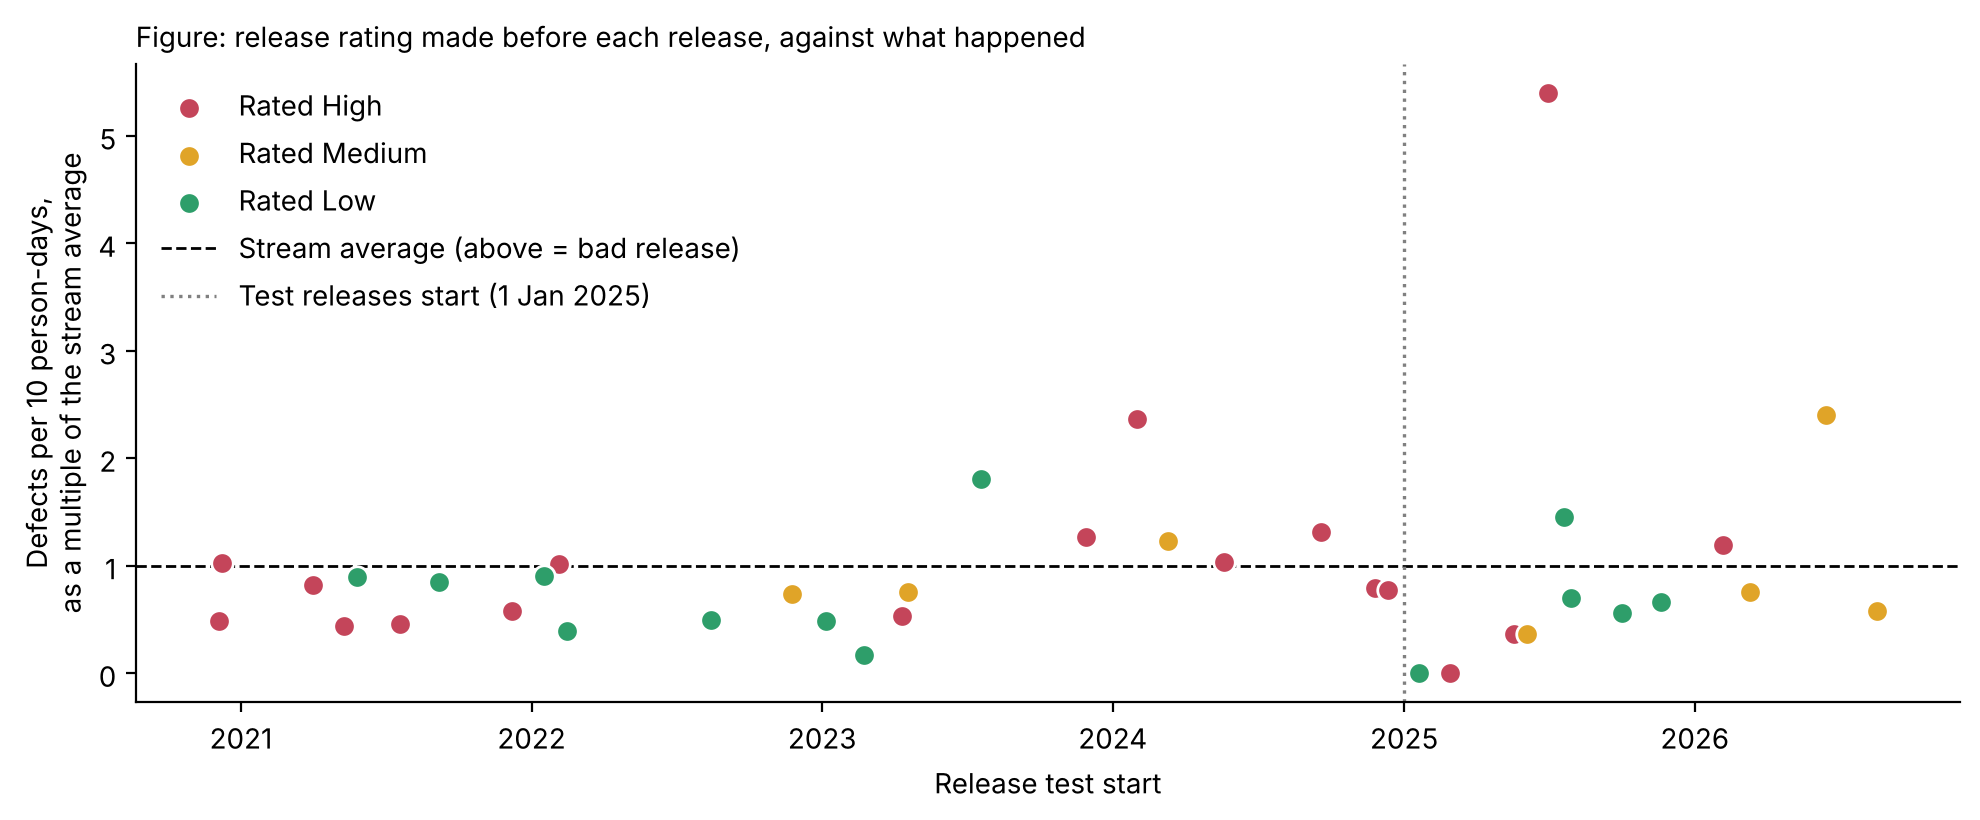

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
colors = {'High': '#c4455a', 'Medium': '#e0a428', 'Low': '#2e9e6a'}
for level in ['High', 'Medium', 'Low']:
    g = per[per.rating_mix == level]
    ax.scatter(g.window_start, g.vs_average, s=60, color=colors[level], label=f'Rated {level}', edgecolor='white', zorder=3)
ax.axhline(1, color='black', linestyle='--', linewidth=1, label='Stream average (above = bad release)')
ax.axvline(pd.Timestamp('2025-01-01'), color='grey', linestyle=':', linewidth=1.2, label='Test releases start (1 Jan 2025)')
ax.set_ylabel('Defects per 10 person-days,\nas a multiple of the stream average')
ax.set_xlabel('Release test start')
ax.set_title('Figure: release rating made before each release, against what happened', loc='left', fontsize=10)
ax.legend(frameon=False, loc='upper left')
for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / 'reports' / 'release_rating.png', dpi=150)
plt.show()

## 4. The next release of each stream: what Hindsight says now

Scored as if each stream's next release starts on 1 November 2026, right after the trackers end, with everything that had finished by then. The model is the one chosen in step 5, retrained on all labelled releases. Each component gets a band, and the release gets a rating with the mixed rule.

In [6]:
from hs_features import load_context, history, FEATURES_CAT
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

NUM = choice.features.split(',')
depth, leaf = eval(choice.setting)
model = Pipeline([('prep', ColumnTransformer([('num', SimpleImputer(strategy='median'), NUM),
                                              ('cat', OneHotEncoder(handle_unknown='ignore'), FEATURES_CAT)])),
                  ('model', RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf,
                                                   class_weight='balanced_subsample', random_state=42, n_jobs=-1))])
learn = fact if bool(choice.keep_estimated) else fact[~fact.effort_estimated.astype(bool)]
model.fit(learn[NUM + FEATURES_CAT], learn.high_risk)

with sqlite3.connect(CLEAN) as cc:
    ctx = load_context(cc)
NEXT_START = pd.Timestamp('2026-11-01')
NEXT_NAME = {'Vendor A': 'Vendor A: next release 1.57', 'Vendor B': 'Vendor B: next release', 'Vendor C': 'Vendor C: next release'}
rows = []
for vendor in NEXT_NAME:
    for comp in sorted(fact[fact.vendor == vendor].component.unique()):
        rows.append({'vendor': vendor, 'component': comp, **history(ctx, vendor, NEXT_START, comp, None)})
nxt = pd.DataFrame(rows)
nxt['score'] = model.predict_proba(nxt[NUM + FEATURES_CAT])[:, 1]
nxt['band'] = np.select([nxt.score >= comp_high, nxt.score >= comp_med], ['High', 'Medium'], 'Low')
nxt['next_release'] = nxt.vendor.map(NEXT_NAME)

def rate(g):
    vendor = g.vendor.iloc[0]
    n_high, w = int((g.band == 'High').sum()), weighted_avg(g)
    share = n_high / len(g)
    level = ('High' if (share >= cut('share_high', vendor) or w >= cut('w_high', vendor)) else
             'Medium' if (share >= cut('share_med', vendor) or w >= cut('w_med', vendor)) else 'Low')
    order = g.sort_values('score', ascending=False)
    return pd.Series({'rating': level, 'high_components': n_high, 'weighted_avg': round(w, 2),
                      'High': ', '.join(order[order.band == 'High'].component),
                      'Medium': ', '.join(order[order.band == 'Medium'].component)})
next_rating = nxt.groupby('next_release', sort=False).apply(rate)
next_rating

,rating,high_components,weighted_avg,High,Medium
next_release,,,,,
Vendor A: next release 1.57,Low,1,0.41,Environment and infrastructure,"Self-checkout (SCO), Reporting, Payments and PED, Receipts and printing, Vendor D, Promotions, pricing and loyalty"
Vendor B: next release,Low,1,0.65,Self-checkout (SCO),"Environment and infrastructure, Receipts and printing"
Vendor C: next release,High,2,0.76,"Scan and go (handsets), Environment and infrastructure","Promotions, pricing and loyalty"


## 5. Save

In [7]:
with sqlite3.connect(CLEAN) as cc:
    per.to_sql('release_rating', cc, if_exists='replace', index=False)
    scores.to_sql('component_scores_banded', cc, if_exists='replace', index=False)
    nxt.to_sql('next_release_scores', cc, if_exists='replace', index=False)
    next_rating.reset_index().to_sql('next_release_rating', cc, if_exists='replace', index=False)
print('saved release_rating', per.shape, '| component_scores_banded', scores.shape,
      '| next_release_scores', nxt.shape, '| next_release_rating', next_rating.shape)

saved release_rating (41, 23) | component_scores_banded (432, 13) | next_release_scores (33, 19) | next_release_rating (3, 5)


## What is next

Step 7: the release-level view and the Tableau extracts (anonymised), with drill-down from release to component to detail tags to defects, plus the vendor page and the upgrade/infra and "Other" sections.